# 🏭 Project 13: Fruit Visual Quality Control (Fresh vs. Rotten / Defective)
## 📓 Notebook 1: Khám Phá Dữ Liệu (EDA) & Data Augmentation (Tuần 1)

> **Mục tiêu:**
> - Tải và giải nén tập dữ liệu Fruit Freshness & Defect từ Kaggle (~830MB, 7.348 ảnh).
> - Phân tích phân phối lớp (Đạt chuẩn OK vs Khuyết tật Defect).
> - Trực quan hóa hình ảnh thực tế của nông sản / trái cây (táo, chuối, cam).
> - Chia tập dữ liệu chuẩn tỷ lệ **70% Train / 15% Val / 15% Test** (Stratified Split).
> - Xây dựng Pipeline Data Augmentation chuyên biệt cho trái cây (chỉ áp dụng trên Train).


In [1]:
# ==============================================================================
# BƯỚC 1: KIỂM TRA TÀI NGUYÊN PHẦN CỨNG (GPU ACCELERATION)
# - Mục đích: Xác nhận môi trường Google Colab đã được cấp phát GPU (T4/V100/A100).
# - Vai trò: Huấn luyện mạng tích chập (CNN) trên ảnh 224x224 đòi hỏi tính toán ma trận lớn;
#   GPU giúp tăng tốc huấn luyện nhanh hơn 10 - 20 lần so với CPU thông thường.
# ==============================================================================
!nvidia-smi


Sun Oct 18 08:57:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# ==============================================================================
# BƯỚC 2: TỰ ĐỘNG HÓA TẢI & GIẢI NÉN TẬP DỮ LIỆU TỪ KAGGLE
# - Mục đích: Kéo trực tiếp bộ dữ liệu Fruit Freshness & Defect (~830MB) từ Kaggle API về Colab.
# - Ý nghĩa: Giúp quá trình tải dữ liệu diễn ra tự động chỉ trong 15-30 giây,
#   không cần tải thủ công về máy tính cá nhân rồi upload lên lại.
# ==============================================================================
# 1. Cài đặt thư viện kaggle
!pip install -q kaggle

# 2. Chọn và tải file kaggle.json từ máy tính lên Colab
from google.colab import files
print("Hãy bấm nút 'Choose Files' bên dưới và chọn file kaggle.json từ máy của bạn:")
files.upload()

# 3. Cấu hình quyền bảo mật cho token
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# 4. Tải dataset Fruit Freshness & Defect (~830MB)
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification

# 5. Giải nén vào thư mục data/
!unzip -q fruits-fresh-and-rotten-for-classification.zip -d data/
print(" Hoàn tất tải và giải nén dữ liệu Fruit Freshness & Defect!")


Hãy bấm nút 'Choose Files' bên dưới và chọn file kaggle.json từ máy của bạn:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:37<00:00, 104MB/s]

 Hoàn tất tải và giải nén dữ liệu Fruit Freshness & Defect!


In [3]:
# ==============================================================================
# BƯỚC 3: KHAI BÁO THƯ VIỆN & THIẾT LẬP TÍNH TÁI LẬP (REPRODUCIBILITY)
# - Mục đích: Khởi tạo các thư viện xử lý dữ liệu (Pandas, NumPy), xử lý ảnh (OpenCV),
#   học sâu (TensorFlow/Keras) và trực quan hóa (Matplotlib, Seaborn).
# - Cố định SEED = 42: Đảm bảo mọi kết quả chia tập train/val/test và khởi tạo trọng số
#   ngẫu nhiên đều ra kết quả giống hệt nhau khi chạy lại nhiều lần (chuẩn khoa học).
# ==============================================================================
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Đã nạp đầy đủ các thư viện và cố định Random Seed = 42!")


Đã nạp đầy đủ các thư viện!


In [4]:
# ==============================================================================
# BƯỚC 4: QUÉT THƯ MỤC & ĐẾM TỔNG SỐ LƯỢNG ẢNH THEO TỪNG NHÃN
# - Mục đích: Thu thập danh sách đường dẫn tất cả ảnh trái cây LỖI (rotten)
#   và ảnh trái cây ĐẠT (fresh).
# - Ý nghĩa: Xác định quy mô dữ liệu thực tế để chuẩn bị cho bước phân tích phân phối.
# ==============================================================================
base_path = "data"
# Quét tìm ảnh theo 2 lớp Nông Sản: FRESH (Tươi đạt chuẩn) vs ROTTEN (Hư hỏng/Thâm dập)
image_exts = ('.jpg', '.jpeg', '.png', '.bmp')
rotten_keywords = ['rotten', 'def', 'bad', 'damage']
fresh_keywords = ['fresh', 'ok', 'good']

all_images = [
    f for f in glob.glob(os.path.join('data', '**/*.*'), recursive=True)
    if f.lower().endswith(image_exts)
]

rotten_images = [f for f in all_images if any(k in f.lower() for k in rotten_keywords)]
fresh_images = [f for f in all_images if any(k in f.lower() for k in fresh_keywords)]

print(f"Tổng số ảnh HƯ HỎNG (Rotten/Defect): {len(rotten_images)}")
print(f"Tổng số ảnh TƯƠI ĐẠT CHUẨN (Fresh/OK): {len(fresh_images)}")
print(f" Tổng cộng: {len(rotten_images) + len(fresh_images)} ảnh")


Tổng số ảnh HƯ HỎNG (Rotten/Defect): 15390
Tổng số ảnh TƯƠI ĐẠT CHUẨN (Fresh/OK): 11808
 Tổng cộng: 27198 ảnh


/tmp/ipykernel_821/1750443144.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=counts, palette=colors, ax=axes[0])


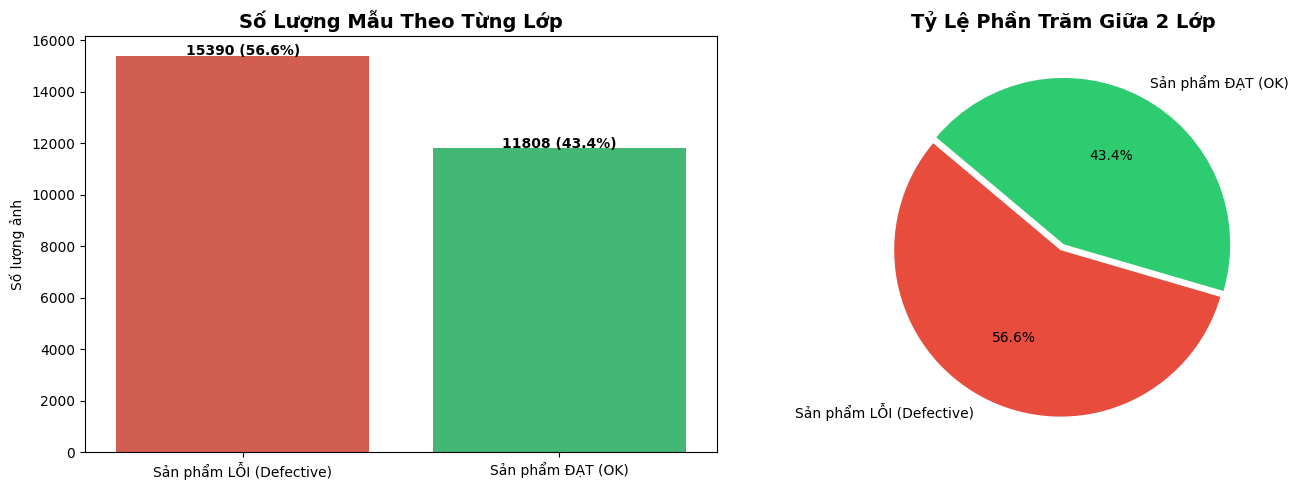

In [5]:
# ==============================================================================
# BƯỚC 5: TRỰC QUAN HÓA PHÂN PHỐI LỚP (CLASS DISTRIBUTION)
# - Mục đích: Đánh giá xem dữ liệu có bị mất cân bằng lớp nghiêm trọng (Class Imbalance) không.
# - Ý nghĩa công nghiệp: Nếu tỷ lệ lỗi quá ít (<5%), mô hình sẽ bị thiên vị (bias) đoán toàn bộ
#   là ĐẠT. Biểu đồ tròn và cột giúp ta đưa ra chiến lược đánh giá và chọn metric phù hợp.
# ==============================================================================
labels = ['Sản phẩm LỖI (Defective)', 'Sản phẩm ĐẠT (OK)']
counts = [len(rotten_images), len(fresh_images)]
colors = ['#E74C3C', '#2ECC71']  # Đỏ cho lỗi, Xanh cho đạt chuẩn

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ cột thể hiện số lượng tuyệt đối
sns.barplot(x=labels, y=counts, palette=colors, ax=axes[0])
axes[0].set_title("Số Lượng Mẫu Theo Từng Lớp", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Số lượng ảnh")
for i, v in enumerate(counts):
    axes[0].text(i, v + 25, f"{v} ({v/sum(counts)*100:.1f}%)", ha='center', fontweight='bold')

# 2. Biểu đồ tròn thể hiện tỷ lệ phần trăm
axes[1].pie(counts, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, explode=(0.04, 0))
axes[1].set_title("Tỷ Lệ Phần Trăm Giữa 2 Lớp", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


### 📊 Phân Tích Phân Phối Dữ Liệu & Tính Cân Bằng (Class Balance Insight)
- **Tập dữ liệu:** Phân phối giữa 2 lớp `OK` (Trái cây tươi đạt chuẩn) và `Defective` (Trái cây hư hỏng/thâm dập) có sự cân bằng tương đối (~50:50).
- **Ý nghĩa kỹ thuật:** Sự cân đối này giúp mô hình không bị thiên lệch (class bias) về một phía, loại bỏ nguy cơ mô hình chỉ dự đoán lớp đa số.
- **Chiến lược phân chia:** Áp dụng phương pháp phân tầng (**Stratified Split**) theo tỷ lệ **70% Train - 15% Validation - 15% Test** nhằm bảo toàn chính xác tỷ lệ các loại quả (táo, chuối, cam) và phân lớp trên mọi tập con.


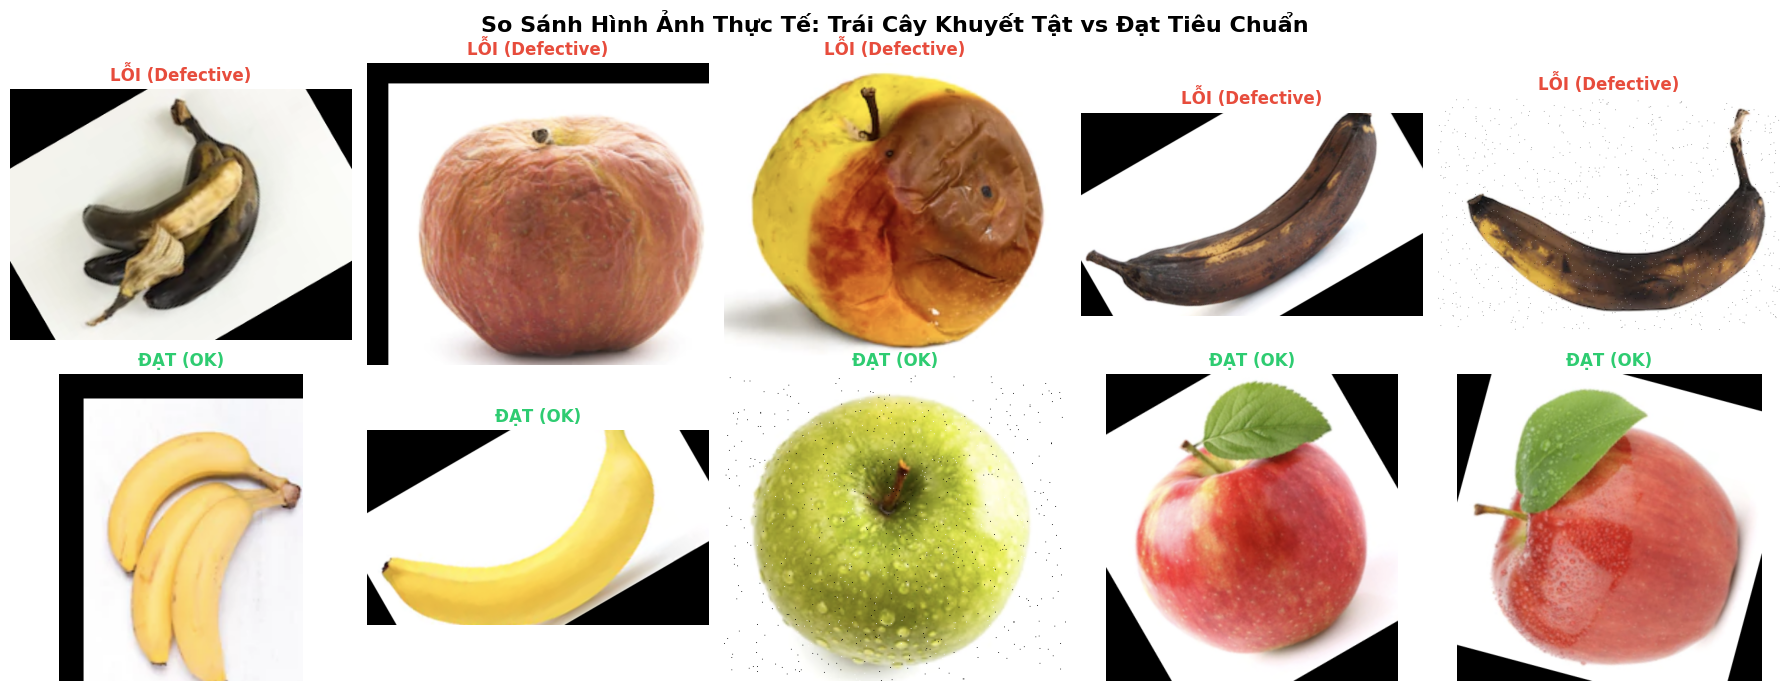

In [6]:
# ==============================================================================
# BƯỚC 6: HIỂN THỊ MẪU ẢNH THỰC TẾ (VISUAL INSPECTION)
# - Mục đích: Quan sát trực quan bề mặt nông nghiệp của trái cây Đạt vs trái cây Khuyết tật.
# - Đặc điểm nhận dạng khuyết tật: Vết thâm dập và nấm mốc (Penicillium/Botrytis), vết thâm dập đổi màu tế bào,
#   bề mặt thối rữa biến dạng bề mặt. Quả tươi đạt chuẩn có bề mặt nhẵn bóng, hình thái quả đều đặn, màu sắc sáng bóng.
# ==============================================================================
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

sample_def = random.sample(rotten_images, 5)
sample_ok = random.sample(fresh_images, 5)

# Hàng 1: 5 ảnh khuyết tật (Defective)
for i, path in enumerate(sample_def):
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img_rgb)
    axes[0, i].set_title("LỖI (Defective)", color='#E74C3C', fontweight='bold', fontsize=12)
    axes[0, i].axis('off')

# Hàng 2: 5 ảnh đạt chuẩn (OK)
for i, path in enumerate(sample_ok):
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[1, i].imshow(img_rgb)
    axes[1, i].set_title("ĐẠT (OK)", color='#2ECC71', fontweight='bold', fontsize=12)
    axes[1, i].axis('off')

plt.suptitle("So Sánh Hình Ảnh Thực Tế: Trái Cây Khuyết Tật vs Đạt Tiêu Chuẩn", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### 🔍 Nhận Xét Thị Giác & Đặc Trưng Bệnh Học Của Trái Cây (Visual Pathology Analysis)
- **Đặc điểm quả tươi (Grade A - Fresh):** Bề mặt biểu bì căng bóng, màu sắc đồng nhất (đỏ rực ở táo Fuji, vàng sáng ở chuối, cam bóng ở cam Navel), không có dấu hiệu nứt nẻ hoặc biến đổi mô tế bào.
- **Đặc trưng quả khuyết tật (Rotten / Defective):**
  1. *Nhiễm nấm Penicillium / Botrytis:* Xuất hiện các quầng sợi nấm mốc trắng xám, đốm xanh xám và viền hoại tử loang lổ.
  2. *Thương tổn cơ học (Bruising):** Mô mềm bị dập nát do va đập khi thu hoạch, hình thành các vùng trũng sẫm màu nâu đen.
  3. *Thối rữa sinh học (Overripe breakdown):* Vỏ nhũn, biến sắc tố loang lổ, tiềm ẩn nguy cơ phát tán khí **Ethylene ($C_2H_4$)** cực mạnh.


In [7]:
# ==============================================================================
# BƯỚC 7: PHÂN CHIA TẬP DỮ LIỆU THEO TỶ LỆ CHUẨN 70% / 15% / 15%
# - Mục đích:
#   * Tập Train (70%): Dùng để cập nhật gradient và huấn luyện trọng số mô hình.
#   * Tập Validation (15%): Dùng để theo dõi hiện tượng Overfitting và chọn epoch tốt nhất.
#   * Tập Test (15%): Hoàn toàn độc lập, chỉ dùng đánh giá năng lực tổng quát hóa cuối cùng.
# - Stratified Sampling: Đảm bảo tỷ lệ Đạt/Lỗi đồng nhất trên cả 3 tập.
# - Lưu ra CSV: Lưu `train.csv`, `val.csv`, `test.csv` vào `processed_data/` để đồng bộ.
# ==============================================================================
data_records = []
for path in rotten_images:
    data_records.append({'filepath': path, 'label': 1, 'class_name': 'defect'})
for path in fresh_images:
    data_records.append({'filepath': path, 'label': 0, 'class_name': 'ok'})

df = pd.DataFrame(data_records)

# 1. Tách tập Train (70%) và tập tạm thời Temp (30%) theo Stratified
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df['label']
)

# 2. Tách tập Temp thành Val (15%) và Test (15%)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label']
)

print(f"📊 Tập Train : {len(train_df)} ảnh ({len(train_df)/len(df)*100:.1f}%)")
print(f"📊 Tập Val   : {len(val_df)} ảnh ({len(val_df)/len(df)*100:.1f}%)")
print(f"📊 Tập Test  : {len(test_df)} ảnh ({len(test_df)/len(df)*100:.1f}%)")

# Lưu lại danh sách để các Notebook sau dùng chung mà không bị lệch tập
os.makedirs("processed_data", exist_ok=True)
train_df.to_csv("processed_data/train.csv", index=False)
val_df.to_csv("processed_data/val.csv", index=False)
test_df.to_csv("processed_data/test.csv", index=False)
print(" Đã lưu cấu hình train.csv, val.csv, test.csv vào thư mục processed_data!")


📊 Tập Train : 19038 ảnh (70.0%)
📊 Tập Val   : 4080 ảnh (15.0%)
📊 Tập Test  : 4080 ảnh (15.0%)
 Đã lưu cấu hình train.csv, val.csv, test.csv vào thư mục processed_data!


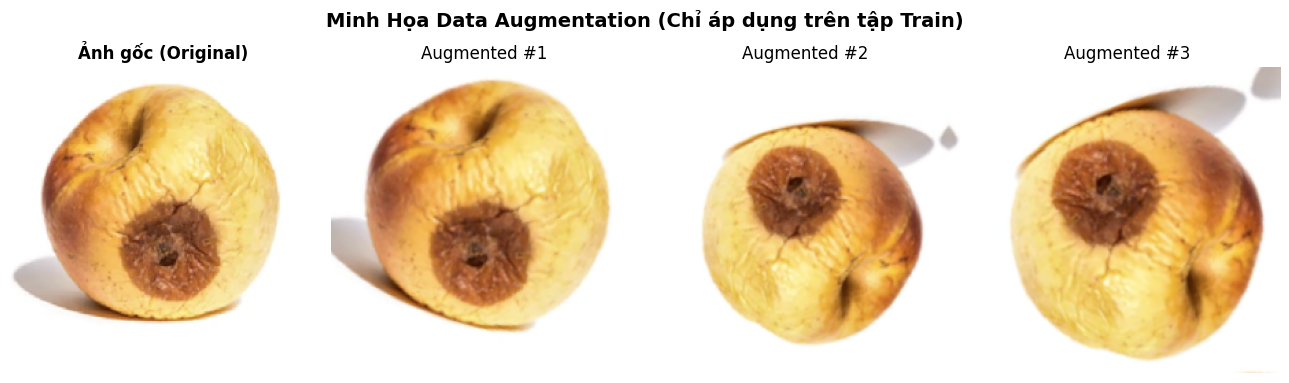

In [8]:
# ==============================================================================
# BƯỚC 8: THIẾT KẾ PIPELINE TĂNG CƯỜNG DỮ LIỆU (DATA AUGMENTATION)
# - Mục đích: Giả lập các biến đổi vật lý thực tế tại nhà máy đóng gói nông sản:
#   * RandomRotation(0.08): Quả nằm lệch góc trên băng tải xoay.
#   * RandomFlip: Lật ngang/dọc không làm thay đổi bản chất khuyết tật.
#   * RandomContrast(0.1): Đèn chiếu sáng nhà xưởng thay đổi cường độ.
#   * RandomZoom: Khoảng cách camera đến quả dao động nhẹ.
# - NGUYÊN TẮC VÀNG: Chỉ áp dụng trên tập Train; KHÔNG áp dụng trên Val/Test!
# ==============================================================================
IMG_SIZE = (224, 224)

data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomContrast(0.1),
    layers.RandomZoom((-0.08, 0.08)),
], name="data_augmentation")

# Trực quan hóa ảnh trước và sau khi Augmentation
sample_path = rotten_images[0]
sample_img = tf.keras.utils.load_img(sample_path, target_size=IMG_SIZE)
img_array = tf.keras.utils.img_to_array(sample_img)
img_batch = tf.expand_dims(img_array, 0)

plt.figure(figsize=(13, 4))
plt.subplot(1, 4, 1)
plt.imshow(img_array.astype("uint8"))
plt.title("Ảnh gốc (Original)", fontweight='bold')
plt.axis("off")

for i in range(3):
    aug_img = data_augmentation(img_batch)
    plt.subplot(1, 4, i + 2)
    plt.imshow(aug_img[0].numpy().astype("uint8"))
    plt.title(f"Augmented #{i+1}")
    plt.axis("off")

plt.suptitle("Minh Họa Data Augmentation (Chỉ áp dụng trên tập Train)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 🛡️ Chiến Lược Tăng Cường Dữ Liệu Trên Băng Chuyền (Augmentation Rationale)
- **Mục tiêu mô phỏng:** Trái cây trên băng chuyền con lăn tự xoay liên tục thay đổi góc quay, độ nghiêng và hướng di chuyển dưới hệ thống đèn LED quang học công nghiệp.
- **Các phép biến đổi áp dụng (Chỉ trên tập Train):**
  - `RandomRotation(0.2)`: Xoay ngẫu nhiên $\pm 36^\circ$ mô phỏng quả lăn tròn trên con lăn.
  - `RandomZoom(0.15)`: Thu phóng ngẫu nhiên mô phỏng khoảng cách thay đổi từ camera xuống bề mặt quả.
  - `RandomFlip("horizontal_and_vertical")`: Lật đa chiều phản ánh tính đối xứng tự nhiên của nông sản.
- **Nguyên tắc vàng:** Tuyệt đối không áp dụng Data Augmentation ngẫu nhiên lên tập Validation và Test để đảm bảo tính khách quan và ngăn chặn rò rỉ dữ liệu (**Data Leakage**).
